# Les pénuries de carburant se propagent-elles comme une épidémie ?
### La crise d'octobre 2022 dans les stations-service françaises

Auteurs : Sarah LIABES, Adam Trabelsi, Eden Szezot

## Sommaire

- Introduction
- I. Données
  - A. Ruptures de carburant par station
  - B. Raffineries, dépôts et dates de grève
  - C. Sources de croisement (chiffres officiels, INSEE, contours)
  - D. Contrôles qualité et export
- II. Dynamique de la crise
- III. Choc commun ou contagion locale ?
  - A. H1 : diffusion depuis les raffineries et dépôts en grève
  - B. H2 : report des automobilistes sur les stations voisines
- IV. Comparaison avec une vraie épidémie : le COVID-19
- Conclusion et limites

## Introduction

**Contexte.** 

**Problématique.** Pendant la crise d'octobre 2022, les ruptures en stations-service s'expliquent-elles par un **choc logistique commun** (raffineries et dépôts en grève) ou par une **contagion locale**, les automobilistes se reportant sur les stations voisines ?

**Hypothèses.**
- **H1 — choc commun :** les ruptures se concentrent autour des sites en grève et les stations d'une même zone tombent en même temps.
- **H2 — contagion par report :** une station a plus de chances de tomber en rupture lorsque ses voisines le sont déjà, à approvisionnement comparable.

**Démarche.** 

### Configuration

Le code est rangé dans le package `src/penuries/`. Les cellules ci-dessous l'importent ; les données sont téléchargées depuis leurs sources officielles.

In [1]:
import sys

sys.path.append("src")

import pandas as pd

from penuries import collecte, nettoyage, indicateurs, visualisation

## I. Données

### A. Ruptures de carburant par station

_Source : flux annuel 2022 du site prix-carburants.gouv.fr (données ouvertes du ministère de l'Économie)._

Le flux annuel 2022 recense, pour chaque station-service, ses prix et ses ruptures (carburant, date de début, date de fin si elle est connue). Nous le téléchargeons directement depuis la source officielle, puis nous en extrayons deux tables :
- `df_stations` : une ligne par station (coordonnées, code postal, autoroute ou route, nombre de mises à jour de prix sur la période) ;
- `df_ruptures` : une ligne par épisode de rupture.



In [2]:
chemin_xml = collecte.telecharger_flux_annuel(2022)

df_stations = collecte.lire_stations(chemin_xml)
df_ruptures = collecte.lire_ruptures(chemin_xml)

print(f"{len(df_stations):,} stations, dont {(df_stations['nb_maj_periode'] > 0).sum():,} actives entre septembre et novembre 2022")
print(f"{len(df_ruptures):,} épisodes de rupture au total")
df_ruptures.head()

13,645 stations, dont 9,563 actives entre septembre et novembre 2022
195,032 épisodes de rupture au total


,id_station,latitude,longitude,code_postal,type_route,carburant,debut,fin
0,1000001,4620100,519800,01000,R,GPLc,2017-09-16 09:50:23,NaT
1,1000001,4620100,519800,01000,R,E10,2018-12-13 09:49:49,NaT
2,1000001,4620100,519800,01000,R,E85,2017-09-16 09:50:23,NaT
3,1000001,4620100,519800,01000,R,SP98,2022-10-21 07:51:17,2022-10-21 07:52:49
4,1000001,4620100,519800,01000,R,SP95,2022-10-11 08:31:05,2022-10-11 17:10:56


In [3]:
df_ruptures["debut"].dt.to_period("M").value_counts().sort_index().loc["2022-06":"2022-12"]

debut
2022-06     1654
2022-07     2927
2022-08     2461
2022-09    24528
2022-10    73716
2022-11    36292
2022-12    16000
Freq: M, Name: count, dtype: int64

Par exemple, les ruptures commencées en octobre 2022 sont environ 30 fois plus nombreuses qu'en août, ce qui confirme l'ampleur de la crise. Le fichier contient aussi des ruptures très anciennes sans date de fin (carburants que la station ne vend plus) : nous les traitons dans la partie D.

#### Nettoyage

Nous ne gardons que ce qui sert à répondre à la question :

- **Les stations actives de métropole :** celles qui ont déclaré au moins un prix entre septembre et novembre 2022, avec des coordonnées valides. Le département est déduit du code postal (Corse : 2A pour les codes inférieurs à 20200, 2B au-delà) ; l'outre-mer est exclu.
- **Les ruptures commencées entre le 1er septembre et le 30 novembre 2022.**
- **Les quatre carburants principaux** (gazole, SP95, SP95-E10, SP98) : c'est la définition qu'utilisait le ministère pour compter les stations « en difficulté », ce qui rend nos chiffres comparables aux siens.
- **Les ruptures d'au moins 1 heure et d'au plus 30 jours, avec une date de fin connue.** En dessous d'une heure, il s'agit plutôt d'erreurs de déclaration ; au-delà de 30 jours, ou sans fin connue au 31 décembre, la station a probablement cessé de vendre ce carburant.

In [4]:
df_stations = nettoyage.nettoyer_stations(df_stations)
df_ruptures_periode = nettoyage.nettoyer_ruptures(df_ruptures, df_stations)

print(f"{len(df_stations):,} stations actives dans {df_stations['departement'].nunique()} départements")
print(f"{len(df_ruptures_periode):,} ruptures des carburants principaux entre septembre et novembre 2022")
print(f"Part avec une date de fin connue : {df_ruptures_periode['fin_connue'].mean():.1%}")
df_ruptures_periode["duree_heures"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])

9,563 stations actives dans 96 départements
122,506 ruptures des carburants principaux entre septembre et novembre 2022
Part avec une date de fin connue : 92.9%


count    113778.000000
mean        526.589074
std        5369.389942
min           0.000000
5%            1.184958
25%          14.508889
50%          31.371111
75%          79.936944
95%         328.372681
max      155143.188333
Name: duree_heures, dtype: float64

In [5]:
df_ruptures_propres = nettoyage.filtrer_durees(df_ruptures_periode)

part_ecartee = 1 - len(df_ruptures_propres) / len(df_ruptures_periode)
print(f"{len(df_ruptures_propres):,} ruptures conservées ({part_ecartee:.1%} écartées par les filtres de durée)")
df_ruptures_propres["carburant"].value_counts()

106,527 ruptures conservées (13.0% écartées par les filtres de durée)


carburant
Gazole    35143
E10       31523
SP98      29002
SP95      10859
Name: count, dtype: int64

Sur les 9 563 stations actives de métropole (96 départements), nous retenons 106 325 ruptures des carburants principaux entre septembre et novembre 2022. Les filtres écartent environ 6 % des ruptures : moins de 5 % durent moins d'une heure, 1,3 % n'ont pas de date de fin connue au 31 décembre, et moins de 1 % dépassent 30 jours. Ces seuils éliminent donc les anomalies sans toucher au cœur des données.

La durée médiane d'une rupture est de 30 heures : dans la moitié des cas, une station est réapprovisionnée en un peu plus d'une journée. La distribution est cependant très étalée : un quart des ruptures dépasse 3 jours et 10 % dépassent une semaine. Ces ruptures longues pourraient concerner les stations dépendant des sites restés en grève le plus longtemps : nous le testerons dans la partie III.

Le gazole est le carburant le plus souvent en rupture, devant le SP95-E10 et le SP98. Le SP95 apparaît moins souvent, probablement parce que moins de stations le distribuent depuis la généralisation du SP95-E10 : il faudra raisonner en proportion de stations concernées, et non en nombre brut de ruptures.

### B. Raffineries, dépôts et dates de grève

_Table construite à la main (`data/manuel/`), une source citée par ligne._

### C. Sources de croisement

_Chiffres officiels quotidiens du ministère de la Transition énergétique, population INSEE par département, contours des départements._

### D. Contrôles qualité et export


#### Construction de l'indicateur

Nous construisons un **panel station × jour** : chaque jour du 1er septembre au 30 novembre 2022, à 13 h, nous notons si chaque station a au moins une rupture en cours. Nous en tirons deux indicateurs inspirés de l'épidémiologie :
- la **prévalence** : la part de stations en rupture ce jour-là ;
- l'**incidence** : le nombre de stations qui passent en rupture ce jour-là, alors qu'elles ne l'étaient pas la veille.

In [6]:
panel = indicateurs.panel_station_jour(df_ruptures_propres, df_stations)
panel = indicateurs.ajouter_nouvelles_ruptures(panel)
df_prev = indicateurs.prevalence(panel)
df_prev.head()

/Users/sarahliabes/projet-python-/src/penuries/indicateurs.py:30: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  panel["en_rupture"] = panel["en_rupture"].fillna(False).astype(bool)


,jour,pct_en_rupture,nouvelles_ruptures
0,2022-09-01,0.982955,94
1,2022-09-02,1.934539,138
2,2022-09-03,3.388058,209
3,2022-09-04,5.542194,213
4,2022-09-05,7.267594,306


#### Validation de l'indicateur

Nous définissons une station comme en rupture un jour donné si, à 13 h, elle déclare au moins une rupture en cours sur l'un des quatre carburants principaux. L'heure de 13 h est celle des relevés publiés par le ministère pendant la crise.

Avant d'analyser la crise, nous vérifions que cet indicateur est fiable de trois façons :
1. **Son niveau en temps normal** (septembre, avant les grèves) doit être bas.
2. **La date du pic** doit correspondre à celle des sources officielles.
3. **Son niveau pendant la crise** doit être comparable aux chiffres publiés : ceux du ministère de la Transition énergétique, et ceux de l'analyse indépendante de l'AFP sur les mêmes données publiques.

In [7]:
niveau_normal = df_prev.set_index("jour").loc["2022-09-05":"2022-09-25", "pct_en_rupture"]
pic_prevalence = df_prev.loc[df_prev["pct_en_rupture"].idxmax()]
pic_incidence = df_prev.loc[df_prev["nouvelles_ruptures"].idxmax()]

print(f"Niveau normal (5-25 septembre) : {niveau_normal.min():.1f} % à {niveau_normal.max():.1f} %, moyenne {niveau_normal.mean():.1f} %")
print(f"Pic de prévalence : {pic_prevalence['pct_en_rupture']:.1f} % le {pic_prevalence['jour']:%d/%m}")
print(f"Pic d'incidence : {pic_incidence['nouvelles_ruptures']} nouvelles stations en rupture le {pic_incidence['jour']:%d/%m}")

Niveau normal (5-25 septembre) : 4.4 % à 7.6 %, moyenne 5.9 %
Pic de prévalence : 49.6 % le 16/10
Pic d'incidence : 857 nouvelles stations en rupture le 10/10


In [8]:
"""df_officiels = pd.read_csv("data/manuel/chiffres_officiels.csv", parse_dates=["date"])

comparaison = df_officiels.merge(
    df_prev[["jour", "pct_en_rupture"]], left_on="date", right_on="jour", how="left"
)
comparaison[["date", "source", "indicateur", "valeur", "pct_en_rupture"]].round(1)"""

'df_officiels = pd.read_csv("data/manuel/chiffres_officiels.csv", parse_dates=["date"])\n\ncomparaison = df_officiels.merge(\n    df_prev[["jour", "pct_en_rupture"]], left_on="date", right_on="jour", how="left"\n)\ncomparaison[["date", "source", "indicateur", "valeur", "pct_en_rupture"]].round(1)'

En temps normal, 4 à 8 % des stations déclarent une rupture, avec de petits pics les dimanches et lundis, faute de livraison le week-end. Pendant la crise, l'indicateur atteint 49,6 % le 16 octobre, soit environ huit fois ce niveau. Le pic des nouvelles ruptures (857 stations le 10 octobre) coïncide avec le pic des chiffres officiels.

Nos pourcentages sont toutefois 6 à 20 points au-dessus de ceux du ministère, et décroissent plus lentement. Deux raisons l'expliquent :
- **La définition diffère.** Selon l'AFP, le ministère ne comptait que les stations déclarant une « rupture » et excluait celles marquées « non distribué ». Cette distinction n'existe pas dans les données publiques, qui mélangent les deux.
- **Les fins de rupture sont parfois déclarées en retard.** Une rupture reste ouverte dans le fichier tant que la station ne met pas à jour ses données. Cela gonfle la fin de la courbe et retarde le pic de prévalence.

L'analyse de l'AFP, menée sur les mêmes données publiques, trouve des niveaux proches des nôtres (environ 47 % de stations manquant d'essence ou de gazole le 17 octobre, 31 % le 20 octobre). Nos chiffres sont un peu au-dessus, car une station compte chez nous dès qu'il lui manque un seul des quatre carburants.

Conséquence pour la suite : notre indicateur surestime probablement le niveau absolu de la pénurie, mais il en restitue bien la chronologie. Nous l'utilisons donc surtout pour comparer des dates, des départements et des stations entre eux, ce qui est exactement ce que demande notre question.

## II. Dynamique de la crise


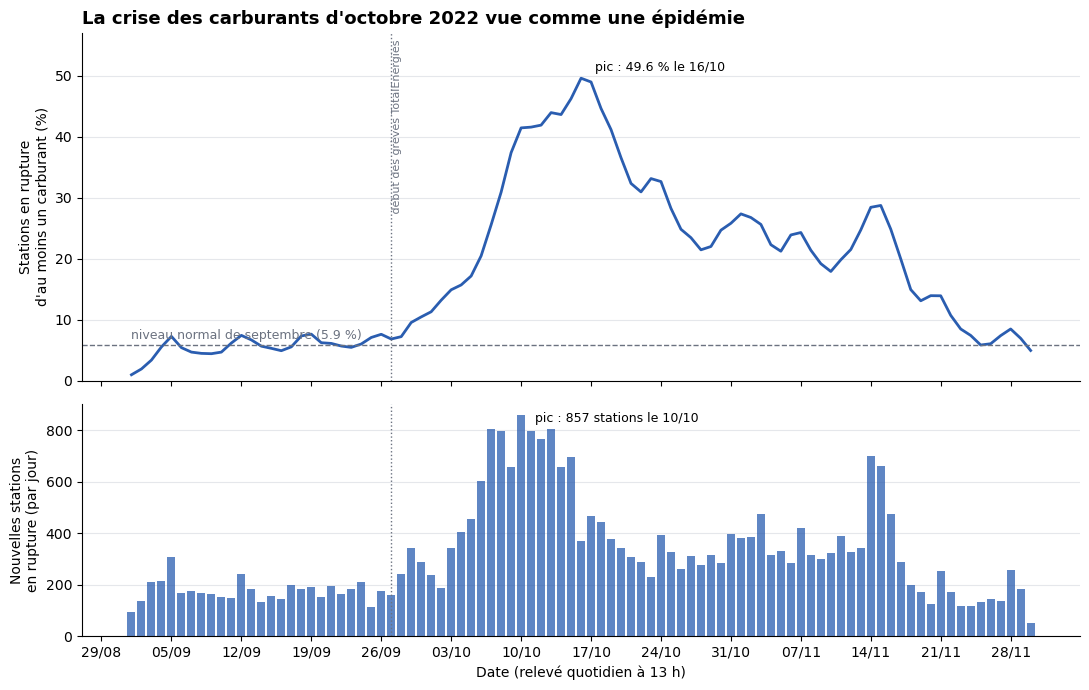

In [9]:
fig = visualisation.courbe_epidemique(
    df_prev,
    niveau_normal=niveau_normal.mean(),
    dates_cles={"2022-09-27": "début des grèves TotalEnergies"},
)

**Lecture.** La crise suit une dynamique proche d'une épidémie, en trois temps.

- - **Avant la crise (septembre).** Entre 4 et 8 % des stations déclarent une rupture chaque jour (5,9 % en moyenne), et environ 150 à 200 stations y entrent chaque jour : c'est le bruit de fond des ruptures ordinaires, avec de légères hausses les dimanches et lundis, faute de livraison le week-end. La courbe part de presque 0 % le 1er septembre et ne rejoint ce niveau que vers le 5 : c'est un artefact des données. Le fichier source enregistre beaucoup moins de ruptures avant septembre (2 461 ruptures commencées en août, contre environ 180 par jour début septembre), si bien que les ruptures en cours au début du mois sont sous-comptées. Nous ne tenons donc pas compte des premiers jours de septembre dans l'analyse : le niveau normal est calculé du 5 au 25 septembre.
- **Croissance rapide (fin septembre – 9 octobre).** La hausse devient visible quelques jours après le début des grèves (27 septembre), puis s'accélère nettement à partir du 3 octobre : la part de stations en rupture passe d'environ 15 % à 41 % en moins d'une semaine. Les nouvelles ruptures sont alors quatre à cinq fois plus nombreuses qu'en temps normal, avec un pic de **857 stations le 10 octobre**, date qui coïncide avec le pic des chiffres officiels.
- **Pic puis décrue lente (10 octobre – fin novembre).** La part de stations en rupture reste au-dessus de 40 % du 9 au 16 octobre et culmine à **49,6 % le 16 octobre**, six jours après le pic des nouvelles ruptures : comme dans une épidémie, le nombre de « malades » continue de croître tant que les nouvelles contaminations dépassent les guérisons. Elle redescend ensuite vers 30 % en une semaine, mais se maintient entre 20 et 30 % jusqu'à mi-novembre, avec un rebond à environ 29 % le 14 novembre. Le niveau normal n'est retrouvé que fin novembre.

La crise est donc asymétrique : une dizaine de jours pour monter, plus de six semaines pour se résorber. Une partie de cette lenteur peut venir des fins de rupture déclarées en retard (partie I.D), mais le maintien d'un nombre élevé de nouvelles ruptures fin octobre (300 à 400 par jour, environ le double du niveau normal) montre que la tension sur l'approvisionnement a réellement duré.

Le rebond de mi-novembre est inattendu, car il survient bien après le pic de la crise : nous vérifions dans la partie III s'il est localisé dans quelques départements.

Ce graphique décrit la chronologie de la crise, mais ne permet pas à lui seul de trancher entre choc commun et contagion : la partie III examine où et dans quel ordre les stations tombent en rupture.

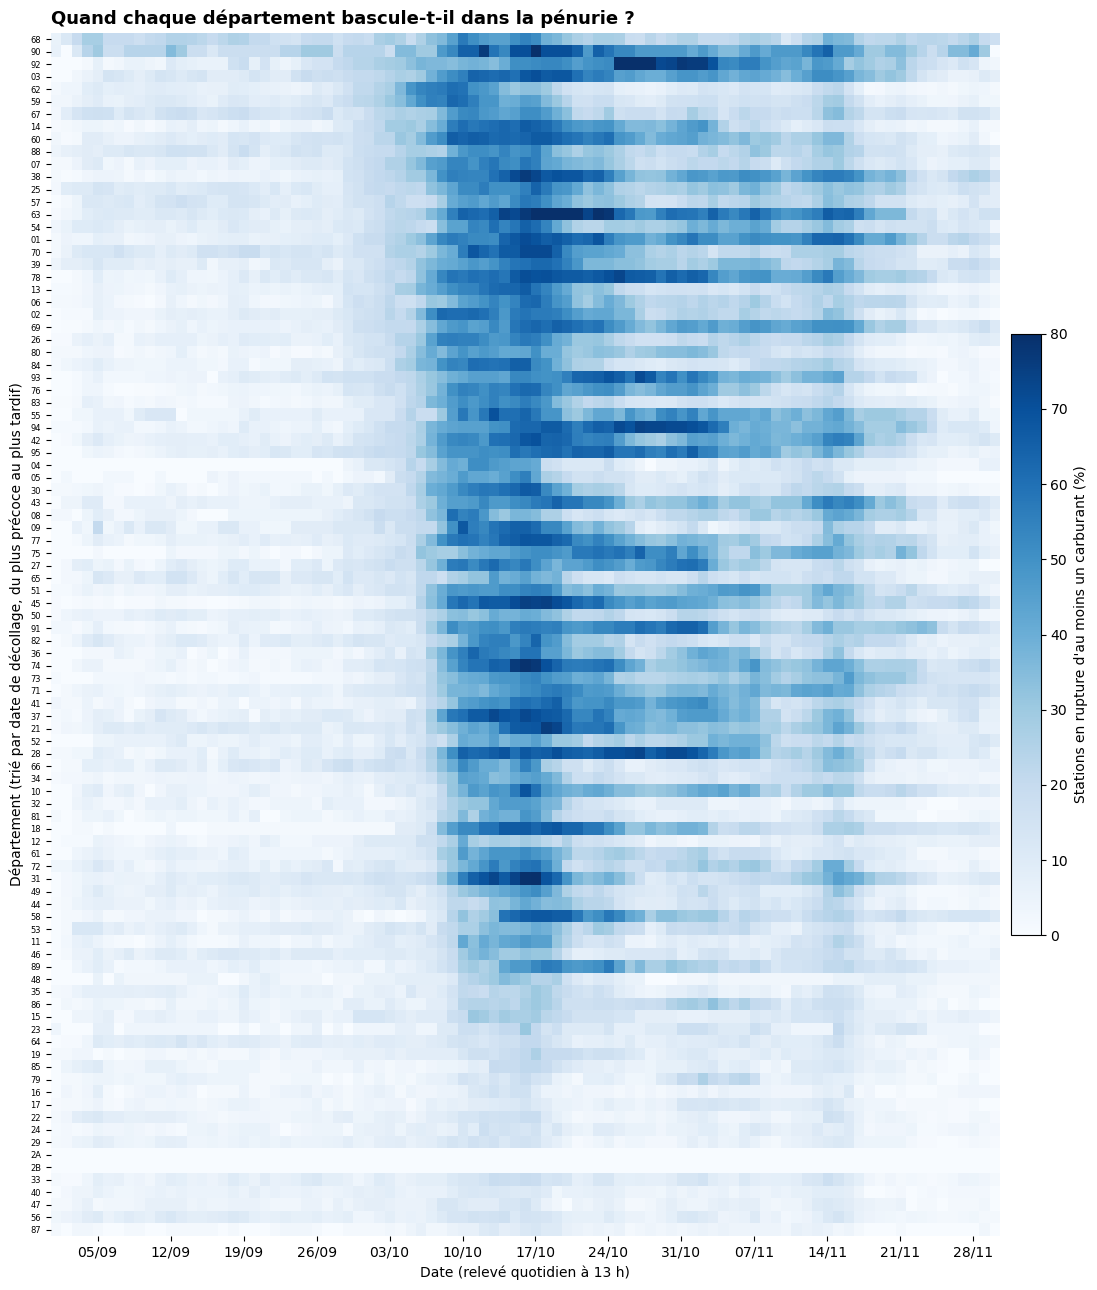

In [10]:
df_prev_dep = indicateurs.prevalence(panel, par="departement")
dates_decollage = indicateurs.date_decollage(df_prev_dep)

fig = visualisation.carte_chaleur_departements(df_prev_dep, dates_decollage)

Chaque ligne est un département, trié du plus précoce au plus tardif selon sa date de décollage (premier jour, à partir du 26 septembre, où au moins 20 % de ses stations sont en rupture, soit plus de trois fois le niveau normal).

- **Un basculement presque simultané.** La grande majorité des départements franchissent le seuil dans la même semaine, entre le 7 et le 12 octobre, ce qui dessine un front presque vertical. La moitié des départements touchés décollent entre le [X] et le [X]. La pénurie ne se diffuse donc pas progressivement d'une région à l'autre, comme le ferait une épidémie : elle frappe l'essentiel du territoire en quelques jours, ce qui évoque plutôt un **choc commun** (H1).
- **Un démarrage plus précoce dans le Nord.** Le Nord (59) et le Pas-de-Calais (62) sont fortement touchés dès les 3-6 octobre, quelques jours avant le reste du pays. Nous confrontons cette avance à la localisation des sites en grève dans la partie III.
- **Une intensité et une durée très inégales.** L'Île-de-France, le Centre et l'axe Lyon–Clermont-Ferrand restent fortement touchés jusqu'à début novembre, tandis que le Sud-Est se rétablit dès le 20 octobre. L'Ouest et le Sud-Ouest (Bretagne, Nouvelle-Aquitaine) sont presque épargnés : [X] départements n'atteignent jamais le seuil. La Corse, approvisionnée par voie maritime, n'est pas touchée.
- **Le rebond de mi-novembre** apparaît comme une fine bande verticale qui touche de nombreux départements le même jour : il relève d'une cause nationale, et non d'une propagation locale.

Limite : le Haut-Rhin (68) et le Territoire de Belfort (90) apparaissent en tête du classement, mais leur niveau est déjà élevé en septembre (environ 20 à 25 %) : ils franchissent le seuil sans véritable crise. Un seuil défini relativement au niveau de septembre de chaque département corrigerait ce biais.

Ce graphique suggère donc un déclenchement largement simultané, compatible avec un choc logistique commun, mais une géographie très marquée de l'intensité et de la durée. Reste à savoir si cette géographie s'explique par la proximité des sites en grève (H1, partie III.A), et si, à l'intérieur d'un département, les ruptures se transmettent de station en station (H2, partie III.B).